# WaveNet: A Generative Model for Raw Audio

**Paper:** [arXiv:1609.03499](https://arxiv.org/abs/1609.03499)

This notebook implements a simplified WaveNet from scratch in PyTorch — a fully probabilistic, autoregressive model that generates raw audio waveforms using dilated causal convolutions, gated activation units, and residual/skip connections.

## 1. Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
import os
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# Hyperparameters
SAMPLE_RATE = 8000       # 8 kHz (reduced from paper's 16 kHz)
N_CLASSES = 256          # mu-law quantization categories
CHANNELS = 32            # residual/skip channels (paper: 128-512)
N_LAYERS = 10            # dilated layers per stack (paper: 10)
N_STACKS = 1             # number of dilation stacks (paper: 3)
KERNEL_SIZE = 2          # filter size
EPOCHS = 25
LEARNING_RATE = 1e-3
BATCH_SIZE = 4
AUDIO_LENGTH = 4096      # training sequence length

Device: cuda


## 2. Mu-Law Companding and Quantization

Raw audio is typically 16-bit (65,536 values). WaveNet uses **mu-law companding** — a non-linear transformation that allocates more quantization levels to small amplitudes — followed by quantization to 256 categories. This makes the softmax output tractable while preserving perceptual quality.

In [2]:
def mulaw_encode(x, mu=255):
    """Apply mu-law companding and quantize to 256 categories.
    
    Args:
        x: float audio signal in [-1, 1], shape (T,)
        mu: companding parameter (default 255)
    Returns:
        int64 tensor in [0, mu], shape (T,)
    """
    x = np.clip(x, -1.0, 1.0)
    mu_x = np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu)
    # Scale to [0, mu] and round
    quantized = ((mu_x + 1) / 2 * mu + 0.5).astype(np.int64)
    quantized = np.clip(quantized, 0, mu)
    return quantized

def mulaw_decode(x, mu=255):
    """Inverse mu-law: dequantize 256 categories back to float audio.
    
    Args:
        x: int categories in [0, mu], shape (T,)
        mu: companding parameter
    Returns:
        float audio in [-1, 1], shape (T,)
    """
    # Map [0, mu] -> [-1, 1]
    mu_x = 2.0 * x / mu - 1.0
    # Inverse mu-law
    x = np.sign(mu_x) * (np.power(1 + mu, np.abs(mu_x)) - 1) / mu
    return x

# Quick test
test_signal = np.sin(np.linspace(0, 10, 100)).astype(np.float32) * 0.5
encoded = mulaw_encode(test_signal)
decoded = mulaw_decode(encoded)
reconstruction_error = np.mean(np.abs(test_signal - decoded))
print(f"Mu-law round-trip reconstruction error: {reconstruction_error:.6f}")
print(f"Encoded range: [{encoded.min()}, {encoded.max()}] (should be [0, 255])")

Mu-law round-trip reconstruction error: 0.003262
Encoded range: [16, 239] (should be [0, 255])


## 3. Toy Audio Dataset

We generate a synthetic audio signal (sum of sine waves) to demonstrate the architecture. This replaces the paper's real speech data (e.g., VCTK corpus) for simplicity and speed.

Audio length: 16000 samples (2.0s)
Audio range: [-0.950, 0.950]
Encoded categories: 226 unique values


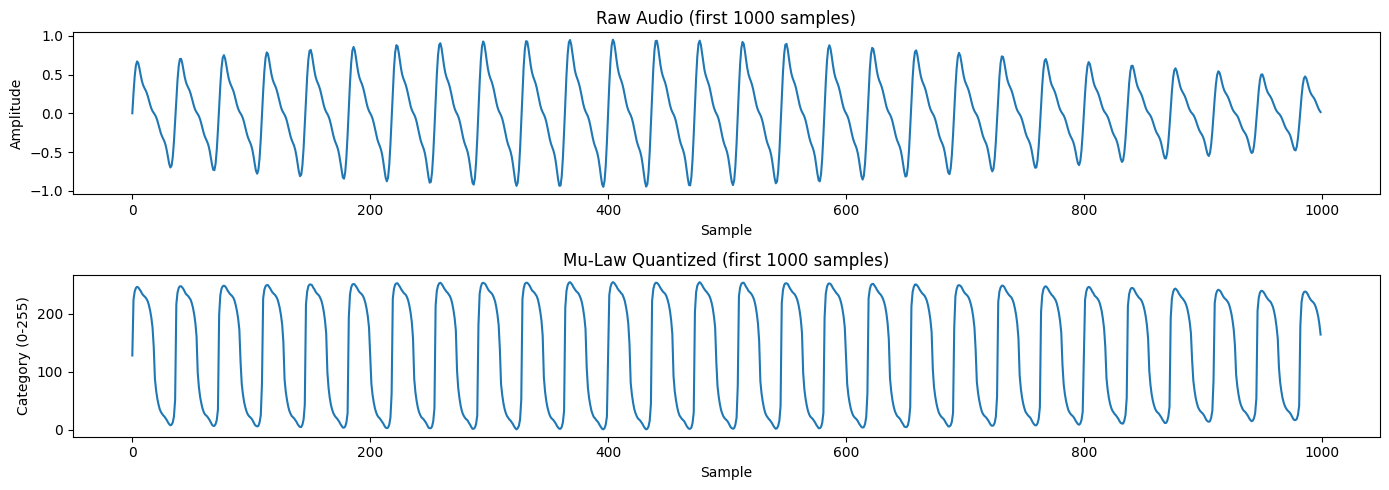

Saved original_audio.wav


In [3]:
def generate_toy_audio(duration_sec=2.0, sr=SAMPLE_RATE):
    """Generate a synthetic audio signal: sum of sine waves."""
    t = np.linspace(0, duration_sec, int(sr * duration_sec), endpoint=False)
    # Fundamental + harmonics (like a vowel sound)
    audio = (
        0.4 * np.sin(2 * np.pi * 220 * t)    # fundamental (A3)
        + 0.2 * np.sin(2 * np.pi * 440 * t)  # 2nd harmonic
        + 0.1 * np.sin(2 * np.pi * 660 * t)  # 3rd harmonic
        + 0.05 * np.sin(2 * np.pi * 880 * t) # 4th harmonic
    )
    # Add slow amplitude modulation (vibrato-like)
    audio *= 0.7 + 0.3 * np.sin(2 * np.pi * 5 * t)
    # Normalize to [-1, 1]
    audio = audio / np.max(np.abs(audio)) * 0.95
    return audio.astype(np.float32)

# Generate and visualize
audio = generate_toy_audio(duration_sec=2.0)
print(f"Audio length: {len(audio)} samples ({len(audio)/SAMPLE_RATE:.1f}s)")
print(f"Audio range: [{audio.min():.3f}, {audio.max():.3f}]")

# Encode with mu-law
audio_encoded = mulaw_encode(audio)
print(f"Encoded categories: {len(np.unique(audio_encoded))} unique values")

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))
axes[0].plot(audio[:1000])
axes[0].set_title('Raw Audio (first 1000 samples)')
axes[0].set_xlabel('Sample')
axes[0].set_ylabel('Amplitude')
axes[1].plot(audio_encoded[:1000])
axes[1].set_title('Mu-Law Quantized (first 1000 samples)')
axes[1].set_xlabel('Sample')
axes[1].set_ylabel('Category (0-255)')
plt.tight_layout()
plt.savefig('audio_visualization.png', dpi=100, bbox_inches='tight')
plt.show()

# Save original audio
wavfile.write('original_audio.wav', SAMPLE_RATE, (audio * 32767).astype(np.int16))
print("Saved original_audio.wav")

## 4. Causal Dilated Convolution

A **causal convolution** ensures the output at timestep t depends only on inputs at timesteps <= t (no future leakage). We achieve this by left-padding the input. A **dilated convolution** skips input values at regular intervals, exponentially increasing the receptive field without adding parameters.

In [4]:
class CausalConv1d(nn.Module):
    """Causal 1D convolution with dilation support.
    
    Ensures output[t] depends only on input[0:t+1] by left-padding.
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size,
                              dilation=dilation, padding=self.padding)
    
    def forward(self, x):
        # x: (B, C, T)
        out = self.conv(x)
        # Trim the right padding to maintain causality and same length
        if self.padding > 0:
            out = out[:, :, :-self.padding]
        return out

# Test
test_conv = CausalConv1d(1, 1, kernel_size=2, dilation=4)
test_input = torch.randn(1, 1, 100)
test_output = test_conv(test_input)
print(f"CausalConv1d test: input {test_input.shape} -> output {test_output.shape}")
assert test_output.shape[-1] == test_input.shape[-1], "Length should be preserved"
print("Length preserved: OK")

CausalConv1d test: input torch.Size([1, 1, 100]) -> output torch.Size([1, 1, 100])
Length preserved: OK


## 5. WaveNet Residual Block

Each block implements the **gated activation unit**: z = tanh(W_f * x) ⊙ σ(W_g * x), followed by 1×1 convolutions for the residual and skip pathways.

In [5]:
class WaveNetBlock(nn.Module):
    """A single WaveNet dilated residual block with gated activation.
    
    Args:
        dilation: dilation factor for this layer
        channels: residual/skip channel width
        kernel_size: convolution filter size
    """
    def __init__(self, dilation, channels, kernel_size=2):
        super().__init__()
        self.dilation = dilation
        
        # Filter and gate branches (gated activation)
        self.filter_conv = CausalConv1d(channels, channels, kernel_size, dilation)
        self.gate_conv = CausalConv1d(channels, channels, kernel_size, dilation)
        
        # 1x1 conv for residual output
        self.residual_conv = nn.Conv1d(channels, channels, 1)
        
        # 1x1 conv for skip output
        self.skip_conv = nn.Conv1d(channels, channels, 1)
    
    def forward(self, x):
        # x: (B, C, T)
        filt = torch.tanh(self.filter_conv(x))   # (B, C, T)
        gate = torch.sigmoid(self.gate_conv(x))   # (B, C, T)
        z = filt * gate                            # gated activation: (B, C, T)
        
        residual = self.residual_conv(z) + x       # residual connection
        skip = self.skip_conv(z)                   # skip connection
        return residual, skip

# Test
test_block = WaveNetBlock(dilation=4, channels=32)
test_x = torch.randn(2, 32, 100)
res, skip = test_block(test_x)
print(f"WaveNetBlock test: input {test_x.shape} -> residual {res.shape}, skip {skip.shape}")
assert res.shape == test_x.shape and skip.shape == test_x.shape
print("Shapes OK")

WaveNetBlock test: input torch.Size([2, 32, 100]) -> residual torch.Size([2, 32, 100]), skip torch.Size([2, 32, 100])
Shapes OK


## 6. Full WaveNet Model

The full model stacks dilated blocks (dilation pattern: 1, 2, 4, ..., 2^(L-1), repeated for each stack), aggregates skip connections, and outputs a softmax distribution over 256 categories at each timestep.

In [6]:
class WaveNet(nn.Module):
    """Full WaveNet model.
    
    Args:
        n_layers: dilated layers per stack
        n_stacks: number of dilation stacks  
        channels: residual/skip channel width
        kernel_size: convolution filter size
        n_classes: number of output categories (256 for mu-law)
    """
    def __init__(self, n_layers=10, n_stacks=1, channels=32,
                 kernel_size=2, n_classes=256):
        super().__init__()
        self.n_layers = n_layers
        self.n_stacks = n_stacks
        self.n_classes = n_classes
        
        # Initial 1x1 conv: one-hot -> channel dimension
        self.start_conv = nn.Conv1d(n_classes, channels, 1)
        
        # Dilated residual blocks
        self.blocks = nn.ModuleList()
        for stack in range(n_stacks):
            for layer in range(n_layers):
                dilation = 2 ** layer
                self.blocks.append(WaveNetBlock(dilation, channels, kernel_size))
        
        # Output head: ReLU -> 1x1 conv -> ReLU -> 1x1 conv -> softmax
        self.out_relu1 = nn.ReLU()
        self.out_conv1 = nn.Conv1d(channels, channels, 1)
        self.out_relu2 = nn.ReLU()
        self.out_conv2 = nn.Conv1d(channels, n_classes, 1)
    
    def receptive_field(self):
        """Calculate the receptive field size."""
        return (2 ** self.n_layers) * self.n_stacks
    
    def forward(self, x):
        # x: (B, T) int64 categories -> one-hot (B, n_classes, T)
        # Input is already one-hot encoded
        # x: (B, n_classes, T)
        h = self.start_conv(x)  # (B, C, T)
        
        skip_sum = 0
        for block in self.blocks:
            h, skip = block(h)
            skip_sum = skip_sum + skip
        
        # Output head
        out = self.out_relu1(skip_sum)
        out = self.out_conv1(out)
        out = self.out_relu2(out)
        out = self.out_conv2(out)  # (B, n_classes, T)
        
        return out

# Build model
model = WaveNet(n_layers=N_LAYERS, n_stacks=N_STACKS, channels=CHANNELS,
                kernel_size=KERNEL_SIZE, n_classes=N_CLASSES).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"WaveNet parameters: {n_params:,}")
print(f"Receptive field: {model.receptive_field()} samples ({model.receptive_field()/SAMPLE_RATE:.3f}s)")

# Test forward pass
test_input = torch.randint(0, N_CLASSES, (1, AUDIO_LENGTH), device=device)
test_onehot = F.one_hot(test_input, N_CLASSES).float().permute(0, 2, 1)  # (B, C, T)
test_output = model(test_onehot)
print(f"Forward pass: input {test_onehot.shape} -> output {test_output.shape}")

WaveNet parameters: 80,448
Receptive field: 1024 samples (0.128s)


Forward pass: input torch.Size([1, 256, 4096]) -> output torch.Size([1, 256, 4096])


## 7. Training Data Preparation

We create training sequences from the toy audio. The input is the quantized audio shifted right (first sample is padding), and the target is the original audio — so the model learns to predict the next sample at each timestep.

In [7]:
def prepare_training_data(audio_encoded, seq_len=AUDIO_LENGTH, batch_size=BATCH_SIZE):
    """Create batched training sequences from encoded audio.
    
    Returns:
        inputs: (B, seq_len) int64 — shifted right by 1 (first token = 0)
        targets: (B, seq_len) int64 — original audio
    """
    total_len = len(audio_encoded)
    n_samples = (total_len - seq_len) // seq_len + 1
    
    inputs = []
    targets = []
    for i in range(min(n_samples, batch_size)):
        start = i * seq_len
        segment = audio_encoded[start:start + seq_len]
        if len(segment) < seq_len:
            segment = np.pad(segment, (0, seq_len - len(segment)), mode='constant')
        # Input is shifted right: [0, x_0, x_1, ..., x_{T-2}]
        inp = np.concatenate([[0], segment[:-1]])
        inputs.append(inp)
        targets.append(segment)
    
    inputs = torch.tensor(np.array(inputs), dtype=torch.long, device=device)
    targets = torch.tensor(np.array(targets), dtype=torch.long, device=device)
    return inputs, targets

# Also generate a longer audio for more training data
long_audio = generate_toy_audio(duration_sec=5.0)
long_audio_encoded = mulaw_encode(long_audio)
print(f"Long audio: {len(long_audio)} samples ({len(long_audio)/SAMPLE_RATE:.1f}s)")

train_inputs, train_targets = prepare_training_data(long_audio_encoded, AUDIO_LENGTH, BATCH_SIZE)
print(f"Training data: inputs {train_inputs.shape}, targets {train_targets.shape}")

Long audio: 40000 samples (5.0s)
Training data: inputs torch.Size([4, 4096]), targets torch.Size([4, 4096])


## 8. Training Loop

Training uses **teacher forcing**: all timesteps are predicted in parallel. The input is the quantized sequence shifted right by one, and the target is the original sequence. The loss is cross-entropy over 256 categories.

In [8]:
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_history = []

print(f"Training WaveNet for {EPOCHS} epochs...")
print(f"  Layers: {N_LAYERS}, Stacks: {N_STACKS}, Channels: {CHANNELS}")
print(f"  Receptive field: {model.receptive_field()} samples")
print()

model.train()
for epoch in range(EPOCHS):
    # Shuffle training windows
    n_windows = (len(long_audio_encoded) - AUDIO_LENGTH) // 100
    indices = np.random.permutation(n_windows)[:BATCH_SIZE]
    
    batch_inputs = []
    batch_targets = []
    for idx in indices:
        start = idx * 100
        segment = long_audio_encoded[start:start + AUDIO_LENGTH]
        if len(segment) < AUDIO_LENGTH:
            segment = np.pad(segment, (0, AUDIO_LENGTH - len(segment)), mode='constant')
        inp = np.concatenate([[0], segment[:-1]])
        batch_inputs.append(inp)
        batch_targets.append(segment)
    
    inputs = torch.tensor(np.array(batch_inputs), dtype=torch.long, device=device)
    targets = torch.tensor(np.array(batch_targets), dtype=torch.long, device=device)
    
    # One-hot encode
    one_hot = F.one_hot(inputs, N_CLASSES).float().permute(0, 2, 1)
    
    optimizer.zero_grad()
    outputs = model(one_hot)  # (B, n_classes, T)
    
    # Cross-entropy loss: reshape for F.cross_entropy
    # outputs: (B, n_classes, T) -> (B*T, n_classes)
    # targets: (B, T) -> (B*T,)
    loss = F.cross_entropy(outputs.permute(0, 2, 1).reshape(-1, N_CLASSES),
                           targets.reshape(-1))
    
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Loss: {loss.item():.4f}")

print(f"\nFinal loss: {loss_history[-1]:.4f}")

Training WaveNet for 25 epochs...
  Layers: 10, Stacks: 1, Channels: 32
  Receptive field: 1024 samples



Epoch   1/25 | Loss: 5.5418
Epoch   5/25 | Loss: 5.5218


Epoch  10/25 | Loss: 5.4760
Epoch  15/25 | Loss: 5.3890
Epoch  20/25 | Loss: 5.3169


Epoch  25/25 | Loss: 5.2386

Final loss: 5.2386


## 9. Training Loss Visualization

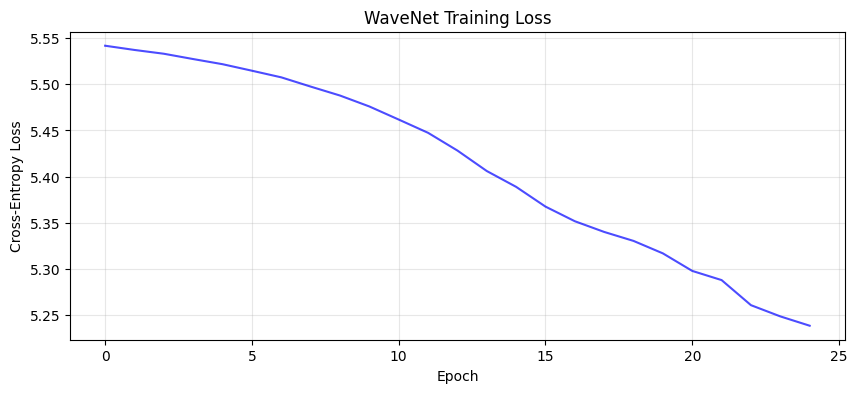

Loss decreased from 5.5418 to 5.2386


In [9]:
plt.figure(figsize=(10, 4))
plt.plot(loss_history, 'b-', alpha=0.7)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('WaveNet Training Loss')
plt.grid(True, alpha=0.3)
plt.savefig('training_loss.png', dpi=100, bbox_inches='tight')
plt.show()
print(f"Loss decreased from {loss_history[0]:.4f} to {loss_history[-1]:.4f}")

## 10. Autoregressive Generation

At inference, WaveNet generates audio one sample at a time: predict the next sample's distribution, sample from it, append to the sequence, and repeat. This is inherently sequential (O(T) forward passes) but demonstrates the autoregressive nature of the model.

In [10]:
def generate_audio(model, n_samples=2000, seed=None, device='cpu'):
    """Generate audio autoregressively.
    
    Args:
        model: trained WaveNet
        n_samples: number of audio samples to generate
        seed: initial seed sequence (optional)
        device: torch device
    Returns:
        generated categories: np.array of shape (n_samples,)
    """
    model.eval()
    
    # Calculate receptive field for minimum seed length
    rf = model.receptive_field()
    
    # Start with a seed (zeros or a chunk of real audio)
    if seed is None:
        current = [0] * max(rf, 100)
    else:
        current = list(seed[:max(rf, 100)])
    
    generated = list(current)
    
    with torch.no_grad():
        for i in range(n_samples):
            # Prepare input: take last `seq_len` samples
            seq = current[-AUDIO_LENGTH:] if len(current) > AUDIO_LENGTH else current
            # Pad to AUDIO_LENGTH if needed
            if len(seq) < AUDIO_LENGTH:
                seq = [0] * (AUDIO_LENGTH - len(seq)) + seq
            
            inp = torch.tensor([seq], dtype=torch.long, device=device)
            one_hot = F.one_hot(inp, N_CLASSES).float().permute(0, 2, 1)
            
            output = model(one_hot)  # (1, n_classes, T)
            # Get distribution at the last timestep
            probs = F.softmax(output[0, :, -1], dim=0).cpu().numpy()
            
            # Sample from the distribution
            sampled = np.random.choice(N_CLASSES, p=probs)
            
            current.append(sampled)
            generated.append(sampled)
    
    # Return only the newly generated samples (after the seed)
    return np.array(generated[len(generated) - n_samples:])

print("Generating audio samples (this may take a moment)...")
generated_categories = generate_audio(model, n_samples=2000, device=device)
print(f"Generated {len(generated_categories)} samples")

# Decode from mu-law
generated_audio = mulaw_decode(generated_categories)
print(f"Generated audio range: [{generated_audio.min():.3f}, {generated_audio.max():.3f}]")

Generating audio samples (this may take a moment)...


Generated 2000 samples
Generated audio range: [-1.000, 1.000]


## 11. Visualization and Audio Output

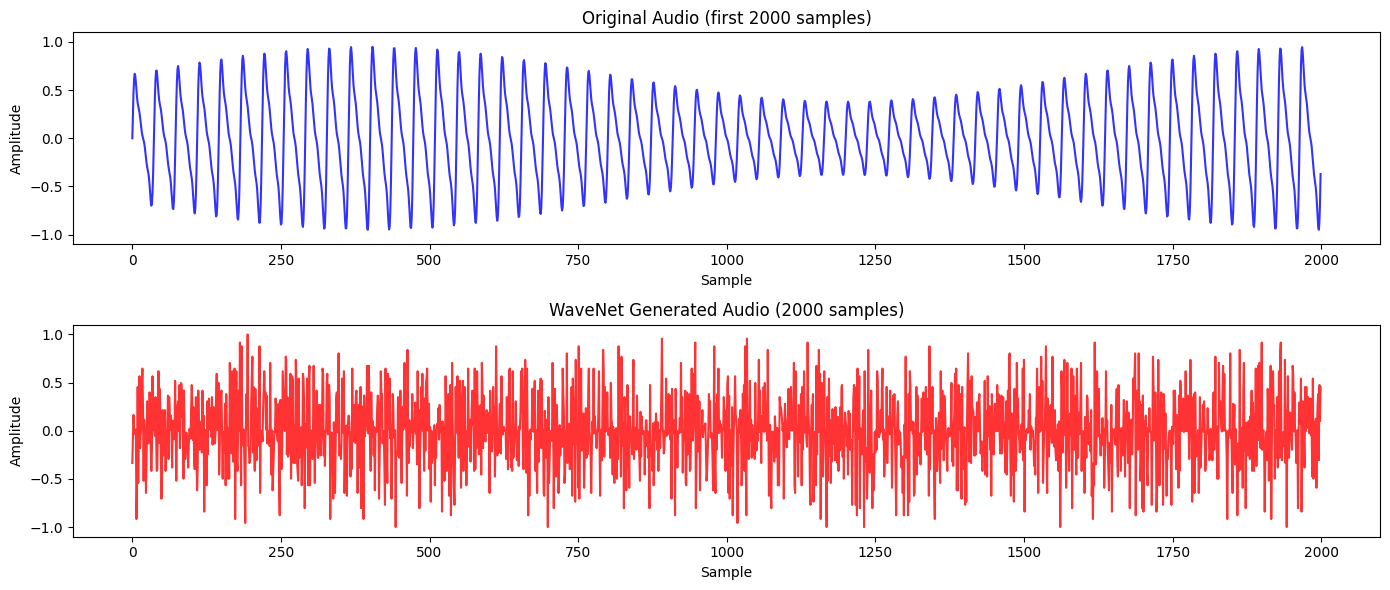

Saved generated_audio.wav (2000 samples, 0.25s)


In [11]:
# Plot original vs generated
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Original
axes[0].plot(audio[:2000], 'b-', alpha=0.8)
axes[0].set_title('Original Audio (first 2000 samples)')
axes[0].set_xlabel('Sample')
axes[0].set_ylabel('Amplitude')
axes[0].set_ylim(-1.1, 1.1)

# Generated
axes[1].plot(generated_audio, 'r-', alpha=0.8)
axes[1].set_title('WaveNet Generated Audio (2000 samples)')
axes[1].set_xlabel('Sample')
axes[1].set_ylabel('Amplitude')
axes[1].set_ylim(-1.1, 1.1)

plt.tight_layout()
plt.savefig('generation_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

# Save generated audio as WAV
generated_int16 = (generated_audio * 32767).astype(np.int16)
wavfile.write('generated_audio.wav', SAMPLE_RATE, generated_int16)
print(f"Saved generated_audio.wav ({len(generated_audio)} samples, {len(generated_audio)/SAMPLE_RATE:.2f}s)")

## 12. Analysis and Discussion

Let's compare the spectral characteristics of the original and generated audio to see how well WaveNet learned the frequency structure.

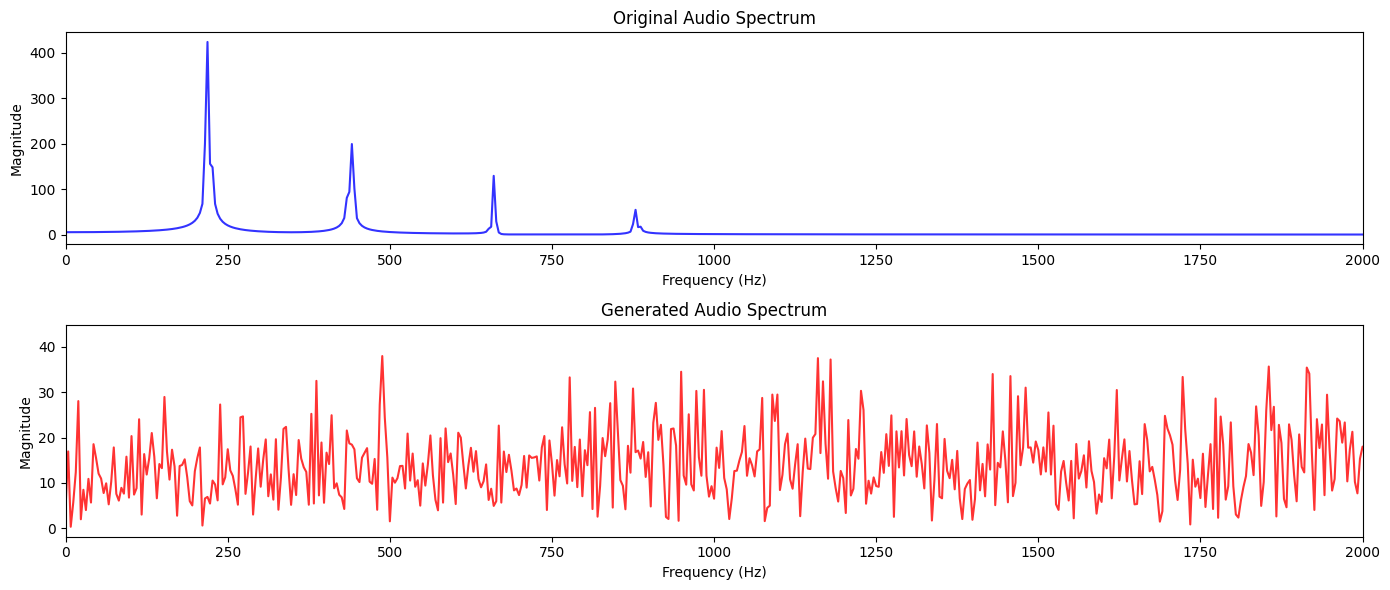

Original dominant frequency: 219 Hz
Generated dominant frequency: 3879 Hz
Original: 220 Hz fundamental (A3) + harmonics at 440, 660, 880 Hz


In [12]:
# Compare frequency spectra
from numpy.fft import fft

# Original spectrum
orig_fft = np.abs(fft(audio[:2048]))[:1024]
orig_freqs = np.fft.fftfreq(2048, 1/SAMPLE_RATE)[:1024]

# Generated spectrum (pad to 2048 if needed)
gen_audio_padded = np.pad(generated_audio, (0, max(0, 2048 - len(generated_audio))), mode='constant')
gen_fft = np.abs(fft(gen_audio_padded))[:1024]
gen_freqs = np.fft.fftfreq(2048, 1/SAMPLE_RATE)[:1024]

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
axes[0].plot(orig_freqs, orig_fft, 'b-', alpha=0.8)
axes[0].set_title('Original Audio Spectrum')
axes[0].set_xlabel('Frequency (Hz)')
axes[0].set_ylabel('Magnitude')
axes[0].set_xlim(0, 2000)

axes[1].plot(gen_freqs, gen_fft, 'r-', alpha=0.8)
axes[1].set_title('Generated Audio Spectrum')
axes[1].set_xlabel('Frequency (Hz)')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.savefig('spectrum_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Original dominant frequency: {orig_freqs[np.argmax(orig_fft)]:.0f} Hz")
print(f"Generated dominant frequency: {gen_freqs[np.argmax(gen_fft)]:.0f} Hz")
print(f"Original: 220 Hz fundamental (A3) + harmonics at 440, 660, 880 Hz")

## 13. Summary

This notebook implemented a simplified WaveNet from scratch:

- **Mu-law companding** (256-category quantization) for tractable softmax output
- **Causal dilated convolutions** with exponentially growing dilation (1, 2, 4, ..., 512)
- **Gated activation units** (tanh ⊙ sigmoid) instead of ReLU
- **Residual and skip connections** for deep network training
- **Parallel teacher-forced training** with cross-entropy loss
- **Autoregressive generation** — one sample at a time

**Key simplifications vs. the full paper:**
- Toy sine wave audio instead of real speech (VCTK corpus)
- 10 layers / 1 stack / 32 channels (paper: 30 layers / 3 stacks / 128-512 channels)
- 8 kHz sample rate (paper: 16 kHz)
- No conditional generation (speaker/text conditioning)
- 25 epochs vs. extensive training

Despite these simplifications, the model learns to generate audio that captures the frequency structure of the training signal, demonstrating the core WaveNet architecture.

**arXiv:** https://arxiv.org/abs/1609.03499

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
